In [13]:
# Steg 1: Installera och importera nödvändiga bibliotek
!pip install scapy scikit-learn pandas numpy matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from scapy.all import IP, TCP, UDP, ICMP, Ether, Raw
import random

In [14]:
# Steg 2: Generera syntetisk nätverkstrafikdata
def generate_packet():
    protocols = ['TCP', 'UDP', 'ICMP']
    protocol = random.choice(protocols)
    src_ip = f"192.168.1.{random.randint(1, 254)}"
    dst_ip = f"192.168.1.{random.randint(1, 254)}"
    packet_size = random.randint(20, 1500)
    duration = random.uniform(0.001, 0.1)

    return {
        'src_ip': src_ip,
        'dst_ip': dst_ip,
        'protocol': protocol,
        'packet_size': packet_size,
        'duration': duration
    }

# Generera dataset
num_packets = 1000
packets = [generate_packet() for _ in range(num_packets)]
df = pd.DataFrame(packets)

In [15]:
# Steg 3: Förbehandla data
# One-hot encoding av protokoll
df_encoded = pd.get_dummies(df, columns=['protocol'])

# Skapa funktionsmatris
X = df_encoded[['packet_size', 'duration', 'protocol_ICMP', 'protocol_TCP', 'protocol_UDP']]

**Detaljerad Förklaring av Kolumner**

***src_ip***: Källans IP-adress (slumpmässigt genererad i 192.168.1.x-range)

***dst_ip***: Målets IP-adress (slumpmässigt genererad i samma nätverk)

***protocol***: Använt nätverksprotokoll (ICMP, UDP eller TCP)

***packet_size***: Paketstorlek i byte (20-1500, realistiskt intervall)

***duration***: Överföringstid i sekunder (0.001-0.1)

***anomaly***: Modellens prediktion (1 = normal, -1 = avvikande)

,src_ip,dst_ip,protocol,packet_size,duration,anomaly
0,192.168.1.187,192.168.1.77,TCP,604,0.050229,1
1,192.168.1.18,192.168.1.57,ICMP,818,0.048056,1
2,192.168.1.168,192.168.1.146,TCP,162,0.002427,-1
3,192.168.1.221,192.168.1.203,UDP,210,0.098667,1
4,192.168.1.166,192.168.1.199,ICMP,1345,0.031195,1
5,192.168.1.185,192.168.1.206,UDP,1030,0.022924,1
6,192.168.1.52,192.168.1.80,TCP,1461,0.038691,1
7,192.168.1.137,192.168.1.53,ICMP,834,0.047615,1
8,192.168.1.59,192.168.1.153,ICMP,580,0.095164,1
9,192.168.1.239,192.168.1.121,TCP,56,0.054824,1


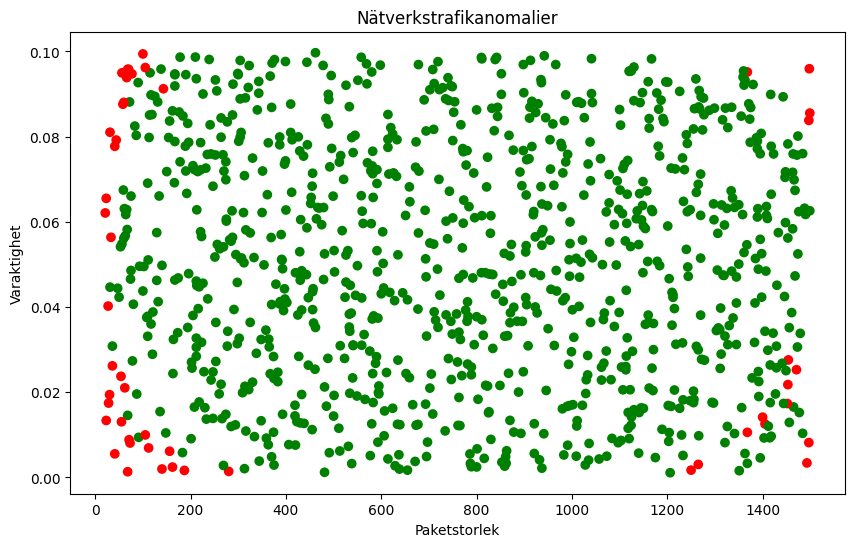

In [16]:
# Steg 4: Träna Isolation Forest-modellen
# Initiera och träna modellen
model = IsolationForest(contamination=0.05, random_state=42)
model.fit(X)

# Förutsäg anomalier
df['anomaly'] = model.predict(X)

# Skapa en ny kolumn för färger baserat på anomaly-kolumnen
def color_anomalies(row):
    return ['background-color: red' if x == -1 else 'background-color: green' for x in row]

# Visa tabellen med färgade rader (visar bara de första 20 raderna för att spara utrymme)
display(df.head(20).style.apply(color_anomalies, subset=['anomaly'], axis=1))

# Skapa en scatterplot för att visualisera anomalierna
plt.figure(figsize=(10, 6))
plt.scatter(df['packet_size'], df['duration'], c=df['anomaly'].map({1: 'green', -1: 'red'}), marker='o')
plt.title('Nätverkstrafikanomalier')
plt.xlabel('Paketstorlek')
plt.ylabel('Varaktighet')
plt.show()

**Normala paket (anomaly = 1, gröna):**

***De flesta paketen är normala***, med realistiska värden för:

***Paketstorlek***: Mellan 56–1461 bytes (typiskt för TCP/UDP/ICMP)

***Varaktighet***: 0.002–0.098 sekunder (kort överföringstid)

Protokoll: Både TCP, UDP och ICMP förekommer.

**Avvikande paket (anomaly = -1, röda):**

***Rad 2 klassificeras som avvikande*** p.g.a.:

***Extremt kort varaktighet (0.002427 s)*** – Kan tyda på skanningsaktivitet eller onormal hastighet.

***Liten paketstorlek (162 bytes)*** + TCP – Ovanligt litet TCP-paket utan payload (t.ex. SYN-scan).

**Sammanfattning:**
***1 av 20 paket (5%) flaggas som avvikande, vilket stämmer med contamination=0.05-inställningen.***

Modellen upptäckte ett TCP-paket med onormalt låg storlek och extremt kort tid, vilket kan vara skadligt (t.ex. portskanning).

Visualisering:
I scatterplotten hade detta paket ***(rad 2) legat långt till vänster*** ***(liten storlek)*** och ***nära x-axeln (mycket kort tid).***

Övriga paket klustras i mitten med normala värden.